### **DES: Brute Force, Weak Keys, and ECB Mode**

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/jrafa1607/Cryptography_In_Python/blob/main/Algorithms/DES_Cipher.ipynb)

> **DES** (1977) encrypts 64-bit blocks with a 56-bit key. It was withdrawn by NIST in 2005, and Triple DES was disallowed after 2023, because a 56-bit key falls to brute force. This notebook checks DES against an official test vector, runs a scaled-down **brute-force attack**, and shows why **ECB mode** leaks patterns.

> [!WARNING]
> Educational code. Never use these implementations to protect real data: use a vetted library (for example, `cryptography`) with modern, authenticated algorithms.

In [1]:
# DES through the cryptography library (Triple DES with three equal keys is exactly single DES)
import os
import time

from cryptography.hazmat.decrepit.ciphers.algorithms import TripleDES
from cryptography.hazmat.primitives.ciphers import Cipher, modes
from cryptography.hazmat.primitives.padding import PKCS7

def des(key8, mode=None):
    return Cipher(TripleDES(key8 * 3), mode or modes.ECB())

def des_encrypt(key8, data):
    enc = des(key8).encryptor()
    return enc.update(data) + enc.finalize()

def des_decrypt(key8, data):
    dec = des(key8).decryptor()
    return dec.update(data) + dec.finalize()

# Known-answer test (classic DES example): key 133457799BBCDFF1, plaintext 0123456789ABCDEF
result = des_encrypt(bytes.fromhex("133457799BBCDFF1"), bytes.fromhex("0123456789ABCDEF"))
print("Ciphertext:", result.hex().upper(), "| expected 85E813540F0AB405")
assert result.hex().upper() == "85E813540F0AB405"

Ciphertext: 85E813540F0AB405 | expected 85E813540F0AB405


In [2]:
# Encrypt and decrypt a message with a random key and PKCS#7 padding
key = os.urandom(8)
padder = PKCS7(64).padder()
plaintext = b"Rafael"
ciphertext = des_encrypt(key, padder.update(plaintext) + padder.finalize())
unpadder = PKCS7(64).unpadder()
recovered = unpadder.update(des_decrypt(key, ciphertext)) + unpadder.finalize()
print(f"Key: {key.hex()} | Ciphertext: {ciphertext.hex()} | Decrypted: {recovered.decode()}")
assert recovered == plaintext

Key: 79b429ac3a3fb73d | Ciphertext: 212396c597ac6c3d | Decrypted: Rafael


#### **01. Brute Force (Scaled Down)**

The full key space is 2^56 (about 72 quadrillion keys), so the demo hides a key in only **2 bytes**. One detail matters: DES ignores the **lowest bit of every key byte** (originally a parity bit). Two key bytes therefore carry only 14 effective bits, and four different keys decrypt correctly. The attack below tests the whole space and finds all four.

In [3]:
# Search the whole 2-byte key space; a known plaintext confirms each candidate
secret_key = bytes.fromhex("BEEF") + bytes(6)
known_plaintext = b"Hello!!!"                       # 8 bytes = one block
target = des_encrypt(secret_key, known_plaintext)

start = time.perf_counter()
candidates = (i.to_bytes(2, "big") + bytes(6) for i in range(2 ** 16))
matches = [k.hex() for k in candidates if des_encrypt(k, known_plaintext) == target]
elapsed = time.perf_counter() - start

print(f"Secret key: {secret_key.hex()}")
print(f"Keys that decrypt correctly: {matches}  (they differ only in the ignored parity bits)")
rate = 2 ** 16 / elapsed
print(f"Tested {2 ** 16:,} keys in {elapsed:.2f} s ({rate:,.0f} keys/s)")
print(f"At this speed, the full 56-bit key space would take about {2 ** 56 / rate / 3600 / 24 / 365:,.0f} years on one CPU core;")
print("dedicated hardware broke DES in 22 hours in 1999 (EFF DES Cracker and distributed.net).")

Secret key: beef000000000000
Keys that decrypt correctly: ['beee000000000000', 'beef000000000000', 'bfee000000000000', 'bfef000000000000']  (they differ only in the ignored parity bits)
Tested 65,536 keys in 0.28 s (234,670 keys/s)
At this speed, the full 56-bit key space would take about 9,737 years on one CPU core;
dedicated hardware broke DES in 22 hours in 1999 (EFF DES Cracker and distributed.net).


#### **02. ECB Mode Leaks Patterns**

In **ECB** (Electronic Codebook) mode, equal plaintext blocks produce equal ciphertext blocks. Encrypting an image with large uniform areas keeps the shapes visible. **CBC** mode chains each block with the previous ciphertext (starting from a random IV), so repeated blocks disappear. This holds for any block cipher, including AES.

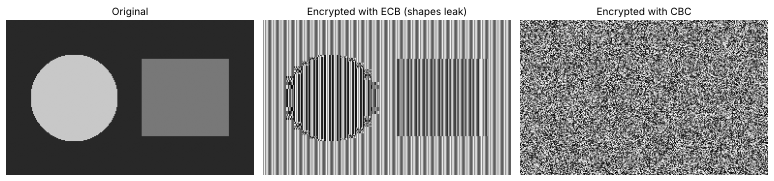

In [4]:
# Encrypt the raw pixels of a simple image with ECB and with CBC
import numpy as np
from matplotlib import pyplot as plt

image = np.full((160, 256), 40, np.uint8)
yy, xx = np.mgrid[:160, :256]
image[(yy - 80) ** 2 + (xx - 70) ** 2 < 45 ** 2] = 200          # circle
image[40:120, 140:230] = 120                                     # rectangle
key = os.urandom(8)

def encrypt_pixels(mode):
    enc = des(key, mode).encryptor()
    return np.frombuffer(enc.update(image.tobytes()) + enc.finalize(), np.uint8).reshape(image.shape)

panels = [image, encrypt_pixels(modes.ECB()), encrypt_pixels(modes.CBC(os.urandom(8)))]
fig, axes = plt.subplots(1, 3, figsize=(13, 3.2))
for ax, panel, title in zip(axes, panels, ["Original", "Encrypted with ECB (shapes leak)", "Encrypted with CBC"]):
    ax.imshow(panel, cmap="gray", vmin=0, vmax=255); ax.set_title(title); ax.axis("off")
plt.tight_layout(); plt.show()

#### **Key Takeaways**

* A 56-bit key is too short; use AES with 128- or 256-bit keys.
* Never use ECB for data larger than one block; prefer an authenticated mode such as AES-GCM (see the AES notebook).
* Known-answer tests confirm that an implementation matches the standard.